# Objective

The objective of this analysis is to evaluate the annual profitability evolution of a selected railway station using historical financial data. The goal is to apply key descriptive statistics concepts to summarize, describe, and understand patterns in the station’s financial performance over time. Specifically, the analysis will compute central tendency measures, assess dispersion, identify potential outliers, and provide a graphical representation of the results.

# Theoretical Concepts

The following variables will be used in the analysis:

- **Station**: Represents the name of the selected railway station. This variable is a categorical data point used to distinguish the financial data for each station.

- **Year**: Refers to the year to which the financial data pertains. This variable is essential for understanding the annual trends and performing time-based analysis on the profitability.

- **Revenues**: This is the total annual income generated by the station, typically in million euros. Revenues are crucial for understanding the station's financial performance and are used in the calculation of profits.

- **Expenses**: Refers to the total annual costs associated with the operation of the station, again in million euros. Like revenues, expenses are used to determine the profitability of the station and can influence its overall financial health.

- **Profit**: Calculated as the difference between **Revenues** and **Expenses** for each year, representing the station’s net earnings. The profit is the key focus of this analysis and is used to calculate central tendency measures and dispersion statistics.

### Descriptive Statistics

To analyse the data, the following measures were computed:

## 1. Measures of Central Tendency

- **Mean**: The arithmetic average of the annual profits, calculated as:
  $$
  \bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i
  $$

- **Median**: The middle value when the profits are sorted. The median is a robust measure of central tendency that is less affected by outliers compared to the mean.

- **Mode**: The most frequent annual profit value. If no value repeats, the mode is considered "None."

## 2. Measures of Dispersion

- **Standard Deviation (Sample)**: Measures the dispersion of the profits around the mean. It is calculated as:
  $$
  s = \sqrt{\frac{1}{n-1} \sum_{i=1}^n (x_i - \bar{x})^2}
  $$

- **Quartiles**: The data is divided into four equal parts:
  - \(Q_1\): 25th percentile (lower quartile),
  - \(Q_2\): 50th percentile (median),
  - \(Q_3\): 75th percentile (upper quartile).



- **Interquartile Range (r_q)**: The range between the first and third quartiles, calculated as:
  $$
  r_q = Q_3 - Q_1.
  $$

- **Outliers**: These are profit values that lie outside the interval:
  $$
  [Q_1 - 1.5 \cdot r_q, \quad Q_3 + 1.5 \cdot r_q].
  $$

## 3. Additional Indicators

- **Most profitable year**: The year with the maximum annual profit.
- **Least profitable year**: The year with the minimum annual profit.

# Graphical Representation

To complement the analysis, a **boxplot** was used to:

- Identify skewness in the distribution;
- Visually locate the median and quartiles;
- Detect outliers.


Error: Station not found. Please enter a valid station name.
Error: Station not found. Please enter a valid station name.
Error: Station not found. Please enter a valid station name.
Error: Station not found. Please enter a valid station name.
Error: Station not found. Please enter a valid station name.
Error: Station not found. Please enter a valid station name.

Statistical Analysis for station: Hamburg

Mean (M€):    16411.738
Standard deviation  (M€):    11413.242
Median (M€):  16635.480
Mode (M€):    None
Most profitable year: 2023 → 43234.230 M€
Least profitable year: 2020 → 3716.370 M€
Outliers (M€): [43234.229999999996]


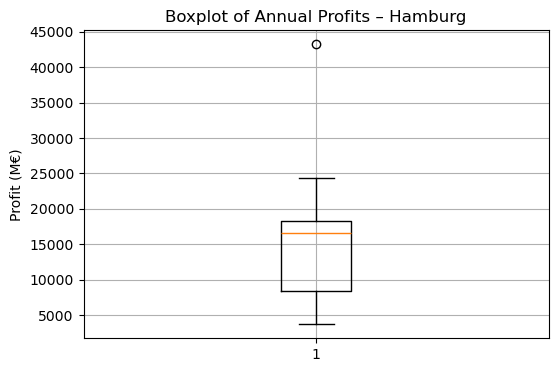

In [20]:
import pandas as pd
import statistics as st
import matplotlib.pyplot as plt

df = pd.read_csv("Stations_Data.csv", sep=';')

for col in df.columns[3:]:
    df[col] = [float(i.replace(",", ".")) for i in df[col].astype(str)]

df["Year"] = df["Year"].astype(int)

df["Profit"] = df["Revenues"] - df["Expenses"]

station = input("Enter the station name: ")
while station not in df["Station"].values:
    print("Error: Station not found. Please enter a valid station name.")
    station = input("Enter the station name: ")

df_s = df[df["Station"] == station]


annual_profit = df_s.groupby("Year")["Profit"].sum()
profits = annual_profit.tolist()

mean_val = st.mean(profits)
median_val = st.median(profits)
std_val = st.stdev(profits)
mode_val = st.mode(profits) if profits.count(st.mode(profits)) > 1 else None


quartiles = st.quantiles(profits, n=4)
Q1, Q2, Q3 = quartiles[0], quartiles[1], quartiles[2]
r_q = Q3 - Q1
lower = Q1 - 1.5 * r_q
upper = Q3 + 1.5 * r_q
outliers = [x for x in profits if x < lower or x > upper]


max_profit = max(profits)
min_profit = min(profits)
best_year = annual_profit.idxmax()
worst_year = annual_profit.idxmin()

print(f"\nStatistical Analysis for station: {station}\n")
print(f"Mean (M€):    {mean_val:.3f}")
print(f"Standard deviation  (M€):    {std_val:.3f}")
print(f"Median (M€):  {median_val:.3f}")
print(f"Mode (M€):    {mode_val if mode_val is not None else 'None'}")
print(f"Most profitable year: {best_year} → {max_profit:.3f} M€")
print(f"Least profitable year: {worst_year} → {min_profit:.3f} M€")
print(f"Outliers (M€): {outliers}")

# Boxplot dos lucros anuais
plt.figure(figsize=(6, 4))
plt.boxplot(profits, vert=True)
plt.title(f"Boxplot of Annual Profits – {station}")
plt.ylabel("Profit (M€)")
plt.grid(True)
plt.show()

# Analysis and Interpretation of Results

The annual profits for the selected station were calculated by subtracting the annual expenses from the revenues. Based on this data, several descriptive statistics were applied to characterize the station’s financial behavior over time.

- The **mean** indicates the average annual profit, while the **median** identifies the central value in the ordered list of profits. The **mode**, when it exists, corresponds to the most frequent profit value. These measures provide insight into the general tendency of the data.

- The **standard deviation** quantifies the dispersion of annual profits around the mean, offering a sense of the variability in financial performance. Higher values suggest greater fluctuations between years.

- To detect potential outliers, the **first** and **third quartiles** (Q1 and Q3) were determined, and the **interquartile range (IQR)** was calculated as:
  $$
  r_q = Q3 - Q1.
  $$
  Outliers were defined as profit values outside the interval:
  $$
  [Q1 - 1.5 \times r_q, \; Q3 + 1.5 \times r_q].
  $$

- A **boxplot** was generated to visualize the distribution of profits. This graphical representation highlights the central tendency, spread, and presence of outliers.

- Additionally, the years corresponding to the **maximum** and **minimum profits** were identified, allowing a more contextual interpretation of financial peaks and troughs.

Understanding the annual profit trends is fundamental in transport network planning and optimization. By identifying financially critical years and analyzing variance, transport authorities or developers of the railway simulation can simulate realistic economic behavior of stations over time.

Moreover, these insights can inform future scenario definitions within the simulator, such as setting economic constraints or targets per station, aligning with the strategic goals of the PI (Projecto Integrador).
